# 07 · Análisis del monitoreo, la deriva, las alertas y la ética operativa

Después de predecir cada lote, el flujo de Kestra `monitoreo.yml` ejecutó `python -m monitoreo.alertas <paso>`: calculó
las métricas del lote, las guardó en `PRODUCCION.MONITOREO` y disparó las alertas de `PRODUCCION.ALERTAS`. Este
notebook analiza lo que quedó registrado:

1. Métricas de sistema y las falsas alarmas de latencia (§1 y §2).
2. Métricas de modelo y de datos (§3 y §4).
3. Deriva de datos con el PSI y las pruebas KS y chi-cuadrado (§5), y deriva conceptual contra la CV (§6).
4. Alertas disparadas y su plantilla (§7), y los reentrenamientos que dispararon (§8).
5. Ética operativa: desempeño por subgrupo, costo de cada error, criterios de retirada, interruptor de respaldo y
   supervisión humana (§9).

La construcción de los lotes y el resultado de negocio están en `06_simulacion_produccion.ipynb`.

In [1]:
import json
import os
import re
import sys
import warnings

sys.path.insert(0, '..')
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from matplotlib.colors import BoundaryNorm, ListedColormap

from monitoreo.alertas import (CADA_N_LOTES, DIAGNOSTICOS, LATENCIA_P95_MAX_MS, N_DESVIACIONES, N_LOTES_DESEMPENO,
                               referencia_cv, tabla_alertas, umbrales)
from monitoreo.deriva import CATEGORICAS_VIGILADAS, NUMERICAS_VIGILADAS, UMBRAL_PSI, UMBRAL_PSI_MODERADO
from src.datos import consultar
from src.lotes import COLUMNAS_X
from src.negocio import CO, CU, ReglaRespaldo, resultado_negocio
from src.reentrenar import tipos_firma

load_dotenv('../.env')
ESQUEMA = 'PSET2_DB.PRODUCCION'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 90)

SERIE, LINEA_BASE, APROBADO, RECHAZADO, CRITICO = '#2a78d6', '#898781', '#0ca30c', '#898781', '#d03b3b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e1e0d9', 'axes.axisbelow': True})

monitoreo = consultar(f'SELECT * FROM {ESQUEMA}.MONITOREO ORDER BY LOTE', 'PSET4_NB07').set_index('LOTE')
for columna in ['PSI', 'PRUEBAS', 'CALIDAD']:
    monitoreo[columna] = monitoreo[columna].map(lambda v: json.loads(v) if isinstance(v, str) else v)
alertas = consultar(f'SELECT * FROM {ESQUEMA}.ALERTAS ORDER BY PASO, LOTE', 'PSET4_NB07')
reentrenamientos = consultar(f'SELECT * FROM {ESQUEMA}.REENTRENAMIENTOS ORDER BY PASO', 'PSET4_NB07')
simulacion = reentrenamientos[reentrenamientos['MOTIVO'] != 'demostracion']

# Registro de solicitudes de la API (una fila por petición HTTP), exportado por src/exportar.py.
solicitudes = pd.read_csv('../docs/solicitudes.csv', encoding='utf-8-sig')
solicitudes['LOTE'] = solicitudes['lote'].str.extract(r'lote-(\d+)-', expand=False).astype('Int64')
solicitudes['momento'] = pd.to_datetime(solicitudes['momento'])
solicitudes = solicitudes.dropna(subset=['LOTE'])        # fuera quedan las pruebas manuales del video
print(f'{len(monitoreo)} lotes en MONITOREO, {len(alertas)} alertas, {len(simulacion)} reentrenamientos en la '
      f'simulación (+{len(reentrenamientos) - len(simulacion)} de demostración), {len(solicitudes)} peticiones de lotes')


def marcar_reentrenamientos(eje, y_texto):
    for _, r in simulacion.iterrows():
        color = APROBADO if r['DECISION'] == 'aprobado' else RECHAZADO
        eje.axvline(r['PASO'] + 0.5, color=color, linestyle='--', linewidth=1)
        eje.text(r['PASO'] + 0.55, y_texto, f"R{r['PASO']} {'✓' if r['DECISION'] == 'aprobado' else '✗'}",
                 color=color, fontsize=8)

10 lotes en MONITOREO, 14 alertas, 3 reentrenamientos en la simulación (+1 de demostración), 74 peticiones de lotes


## 1. Métricas de sistema

Salen del registro de solicitudes de la API: cada petición `POST /predecir/lote` lleva el identificador del lote y la
API anota su código de respuesta y su latencia. Cada lote son 7 peticiones de 2.000 productos (una por día de la
semana); el lote 3 tiene 11, por los tres bloques rechazados y reenviados y un bloque final de 3 filas.

In [2]:
sistema = monitoreo[['PETICIONES', 'PRODUCTOS', 'ERRORES_CLIENTE', 'ERRORES_SERVIDOR', 'TASA_ERRORES_CLIENTE',
                      'TASA_ERRORES_SERVIDOR', 'LATENCIA_P50_MS', 'LATENCIA_P95_MS']].copy()
sistema['DURACION_LOTE_S'] = solicitudes.groupby('LOTE').apply(
    lambda s: (s['momento'].max() - s['momento'].min()).total_seconds() + s['latencia_ms'].iloc[-1] / 1000,
    include_groups=False)
sistema.round(3)

,PETICIONES,PRODUCTOS,ERRORES_CLIENTE,ERRORES_SERVIDOR,TASA_ERRORES_CLIENTE,TASA_ERRORES_SERVIDOR,LATENCIA_P50_MS,LATENCIA_P95_MS,DURACION_LOTE_S
LOTE,,,,,,,,,
1,7,13983,0,0,0.000,0.0,196.724,243.184,1.447
2,7,13998,0,0,0.000,0.0,186.849,233.427,1.419
3,11,14000,3,0,0.273,0.0,174.374,239.068,1.371
4,7,14000,0,0,0.000,0.0,171.084,257.697,1.377
5,7,14000,0,0,0.000,0.0,237.688,1909.703,1.596
6,7,14000,0,0,0.000,0.0,270.917,3181.336,10.272
7,7,14000,0,0,0.000,0.0,205.042,236.978,1.477
8,7,14000,0,0,0.000,0.0,185.525,213.760,1.368
9,7,14000,0,0,0.000,0.0,221.359,852.151,2.209


- **Volumen:** 14.000 productos por lote (13.983 y 13.998 en los lotes 1 y 2), como se esperaba.
- **Errores 5xx:** ninguno en los 10 lotes.
- **Errores 4xx:** solo en el lote 3 (3 de 11 peticiones, 27 %): los tres bloques que traían una fila defectuosa. Es
  una alerta verdadera: la deriva inducida incluía esas filas.
- **Latencia:** la mediana se mantiene entre 160 y 270 ms por petición de 2.000 productos. El p95 supera el umbral
  de 500 ms en los lotes 5, 6 y 9, que no tienen ninguna alteración de sistema. Son las falsas alarmas de §2.

## 2. Las falsas alarmas de latencia

El enunciado pide documentar las falsas alarmas y explicar cómo se ajustaría el umbral. Se miran las peticiones una
por una.

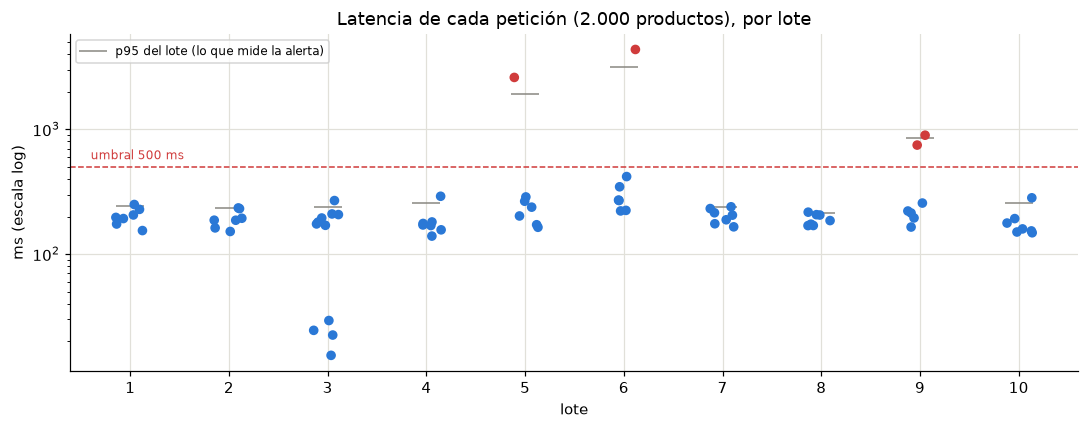

,LOTE,momento,latencia_ms,posicion_en_el_lote,segundos_sin_trafico
32,5,2026-11-23 13:22:59.051267,2605.1,1,36116.2
45,6,2026-11-23 13:23:48.764774,4365.6,7,4.4
60,9,2026-11-23 13:36:50.732435,747.5,1,703.2
65,9,2026-11-23 13:36:52.598562,897.0,6,0.9


In [3]:
figura, eje = plt.subplots(figsize=(10, 4))
rng = np.random.default_rng(0)
for lote, grupo in solicitudes.groupby('LOTE'):
    x = lote + rng.uniform(-0.15, 0.15, len(grupo))
    colores = np.where(grupo['latencia_ms'] > LATENCIA_P95_MAX_MS, CRITICO, SERIE)
    eje.scatter(x, grupo['latencia_ms'], c=colores, s=28, zorder=3)
eje.plot(sistema.index, sistema['LATENCIA_P95_MS'], color=LINEA_BASE, marker='_', markersize=18, linestyle='none',
         label='p95 del lote (lo que mide la alerta)')
eje.axhline(LATENCIA_P95_MAX_MS, color=CRITICO, linestyle='--', linewidth=1)
eje.text(0.6, LATENCIA_P95_MAX_MS * 1.15, f'umbral {LATENCIA_P95_MAX_MS:.0f} ms', color=CRITICO, fontsize=8)
eje.set_yscale('log')
eje.set(title='Latencia de cada petición (2.000 productos), por lote', xlabel='lote', ylabel='ms (escala log)',
        xticks=range(1, 11))
eje.legend(loc='upper left', fontsize=8)
figura.tight_layout()
plt.show()

lentas = solicitudes[solicitudes['latencia_ms'] > LATENCIA_P95_MAX_MS].copy()
anterior = solicitudes['momento'].shift()
solicitudes['segundos_sin_trafico'] = (solicitudes['momento'] - anterior).dt.total_seconds()
lentas = lentas.join(solicitudes['segundos_sin_trafico'])
lentas['posicion_en_el_lote'] = [int((solicitudes.loc[solicitudes['LOTE'] == r.LOTE].index < i).sum()) + 1
                                 for i, r in lentas.iterrows()]
lentas[['LOTE', 'momento', 'latencia_ms', 'posicion_en_el_lote', 'segundos_sin_trafico']].round(1)

Las tres alertas las causó **una sola petición, o dos**, de las 7 del lote. El resto del lote respondió en tiempos
normales (160–420 ms):

- **Lote 5:** la primera petición después de **10 horas sin tráfico** (la simulación quedó en pausa durante la noche,
  esperando la aprobación del paso 4) tardó 2,6 s. Es el arranque en frío: cachés vacías después de la inactividad.
- **Lote 9:** la primera petición después de 12 minutos sin tráfico, durante los cuales corrió el reentrenamiento del
  paso 8 en la misma máquina, tardó 0,75 s; otra petición del mismo lote, 0,9 s.
- **Lote 6:** la última petición tardó 4,4 s, sin inactividad previa. Es un pico aislado: no se repite en el lote
  siguiente ni tiene relación con los datos. La causa más probable es la contención de CPU con otros contenedores
  (Kestra, MLflow) en la misma máquina.

**Por qué el umbral produce falsas alarmas:** con 7 peticiones por lote, el p95 es prácticamente el máximo. Una sola
petición lenta basta para disparar la alerta, aunque el pedido de la semana completo tarde 1,6 s en vez de 1,4 s
(lote 5). En un servicio batch semanal, esa demora no tiene ninguna consecuencia para el negocio.

In [4]:
p95_actual = sistema['LATENCIA_P95_MS'] > LATENCIA_P95_MAX_MS
alternativas = pd.DataFrame({
    'p95 > 500 ms (actual)': p95_actual,
    'p50 > 500 ms': sistema['LATENCIA_P50_MS'] > LATENCIA_P95_MAX_MS,
    'p95 > 500 ms en 2 lotes seguidos': p95_actual & p95_actual.shift(fill_value=False),
    'duración del lote > 30 s': sistema['DURACION_LOTE_S'] > 30,
})
print('Lotes que dispararían la alerta de latencia con cada regla:')
pd.DataFrame({regla: [', '.join(map(str, serie[serie].index)) or 'ninguno'] for regla, serie in alternativas.items()},
             index=['lotes']).T

Lotes que dispararían la alerta de latencia con cada regla:


,lotes
p95 > 500 ms (actual),"5, 6, 9"
p50 > 500 ms,ninguno
p95 > 500 ms en 2 lotes seguidos,6
duración del lote > 30 s,ninguno


**Ajuste propuesto.** Cambiar la métrica de la alerta, no solo el número:

1. **Alertar con la mediana (p50 > 500 ms)**, que mide una degradación sostenida del servicio. No se habría
   disparado en ningún lote.
2. **Alertar por la duración total del lote** (más de 30 s para 14.000 productos), que es lo que importa en un patrón
   batch: el pedido tiene que estar listo para la reunión del lunes. Tampoco se habría disparado; el lote más lento
   (6) tardó 10 s.
3. **Dejar el p95 por petición como registro informativo**, sin alerta, y mandar una petición de calentamiento antes
   del primer bloque después de un período sin tráfico.

Exigir 2 lotes seguidos con p95 alto no basta: el lote 6 seguiría alertando. Las tres falsas alarmas se habrían
evitado con los puntos 1 y 2, que se aplicarían en `monitoreo/alertas.py` (`LATENCIA_P95_MAX_MS` pasa a un umbral
sobre `latencia_p50_ms` y se agrega uno sobre la duración del lote).

## 3. Métricas de modelo

La distribución de los pedidos servidos y la tasa de cada decisión (`reponer` si el pedido es de al menos 0,5
unidades, `no reponer` si no). No necesitan el target: se conocen el mismo día de la predicción.

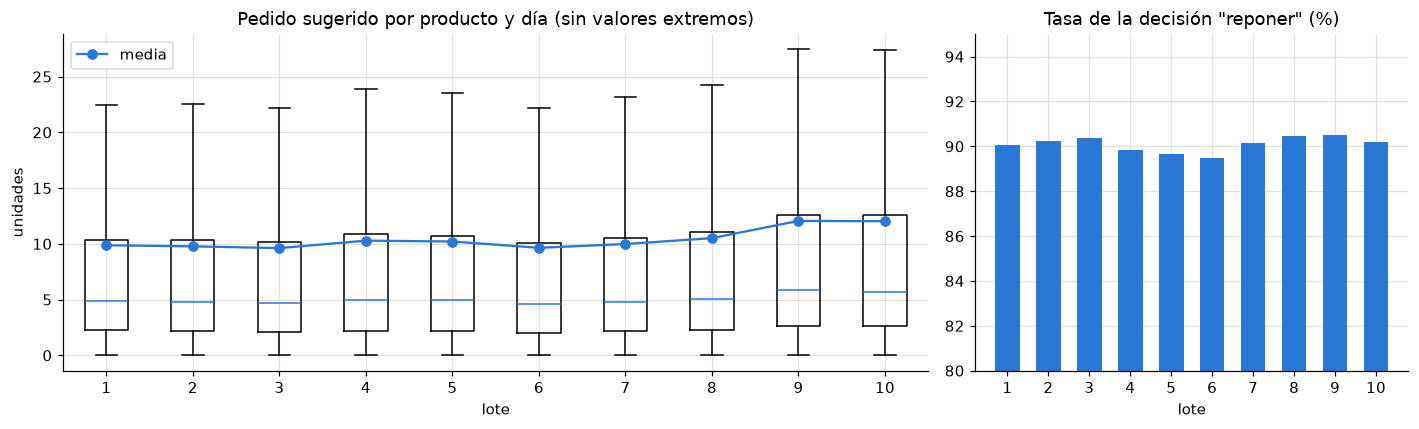

LOTE,1,2,3,4,5,6,7,8,9,10
PEDIDO_MEDIO,9.871,9.774,9.617,10.286,10.207,9.643,9.985,10.510,12.056,12.026
PEDIDO_P50,4.835,4.757,4.651,4.928,4.938,4.607,4.816,5.082,5.821,5.725
PEDIDO_P95,33.620,32.508,32.674,35.010,33.815,32.250,33.460,35.112,40.856,40.946
TASA_REPONER,0.901,0.902,0.904,0.898,0.897,0.895,0.901,0.905,0.905,0.902
USO_RESPALDO_PCT,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [5]:
pedidos = consultar(f'SELECT LOTE, PEDIDO, DECISION FROM {ESQUEMA}.PREDICCIONES', 'PSET4_NB07')
figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
eje1.boxplot([pedidos.loc[pedidos['LOTE'] == k, 'PEDIDO'] for k in range(1, 11)], positions=range(1, 11),
             showfliers=False, medianprops={'color': SERIE}, widths=0.5)
eje1.plot(range(1, 11), pedidos.groupby('LOTE')['PEDIDO'].mean(), marker='o', color=SERIE, label='media')
eje1.set(title='Pedido sugerido por producto y día (sin valores extremos)', xlabel='lote', ylabel='unidades')
eje1.legend()
tasa = pedidos.assign(reponer=pedidos['DECISION'] == 'reponer').groupby('LOTE')['reponer'].mean() * 100
eje2.bar(tasa.index, tasa, color=SERIE, width=0.6)
eje2.set(title='Tasa de la decisión "reponer" (%)', xlabel='lote', ylim=(80, 95), xticks=range(1, 11))
figura.tight_layout()
plt.show()
monitoreo[['PEDIDO_MEDIO', 'PEDIDO_P50', 'PEDIDO_P95', 'TASA_REPONER', 'USO_RESPALDO_PCT']].round(3).T

- **La distribución de pedidos es estable en los lotes 1 a 8** y se desplaza hacia arriba en los lotes 9 y 10 (media
  de 12 unidades contra 10, p95 más alto). Es la primera señal en las predicciones del aumento de demanda, y llega
  cuando las entradas ya lo recogen (§5).
- **La tasa de `reponer` se mantiene entre 89 y 91 %** en todos los lotes. El cambio de demanda mueve el tamaño del
  pedido, no la decisión de reponer: las series con venta casi nula siguen sin pedido.
- **Ninguna predicción usó la regla de respaldo** durante la simulación.

## 4. Métricas de datos

Contra el contrato de entrada de la API (`api/contrato.json`): porcentaje de faltantes por feature, valores fuera de
rango y categorías no vistas en el entrenamiento. Las features de historia admiten nulos (series jóvenes sin 28 días
de venta); los campos de calendario y las categorías no.

In [6]:
faltantes = pd.DataFrame({lote: c['faltantes'] for lote, c in monitoreo['CALIDAD'].items()}).T * 100
faltantes = faltantes.loc[:, faltantes.max() > 0]
print('Faltantes por feature (% de las filas del lote), solo las features con algún faltante:')
display(faltantes.round(3))

calidad = pd.DataFrame({
    'faltantes_obligatorios': monitoreo['FALTANTES_OBLIGATORIOS'],
    'fuera_de_rango': monitoreo['FUERA_DE_RANGO_TOTAL'],
    'categorias_no_vistas': monitoreo['CATEGORIAS_NO_VISTAS_TOTAL'],
    'detalle': monitoreo['CALIDAD'].map(lambda c: ', '.join(
        f'{tipo} en {col}' for tipo in ['fuera_de_rango', 'categorias_no_vistas']
        for col, n in c[tipo].items() if n) or '-')})
calidad

Faltantes por feature (% de las filas del lote), solo las features con algún faltante:


,DAY_OF_MONTH,dias_sin_venta_16,frac_ceros_28_desde_16,media_28_desde_16,media_7_desde_16,media_mismo_dia_4,nivel_serie_16,std_28_desde_16,transacciones_lag_16,venta_lag_16,venta_lag_21,venta_lag_28,venta_lag_35,venta_lag_42
1,0.000,0.308,1.101,1.101,0.436,0.665,0.708,1.101,0.308,0.308,0.665,1.037,1.445,1.788
2,0.000,0.207,0.814,0.814,0.236,0.300,0.357,0.814,0.207,0.207,0.300,0.772,1.143,1.550
3,0.007,0.136,0.371,0.371,0.164,0.186,0.200,0.371,0.136,0.136,0.186,0.314,0.785,1.157
4,0.000,0.043,0.200,0.200,0.071,0.121,0.129,0.200,0.043,0.043,0.121,0.186,0.314,0.786
5,0.000,0.000,0.129,0.129,0.000,0.014,0.029,0.129,0.000,0.000,0.014,0.121,0.186,0.314
6,0.000,0.000,0.029,0.029,0.000,0.000,0.000,0.029,0.000,0.000,0.000,0.014,0.121,0.186
7,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.014,0.121
8,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.014
9,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
10,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


,faltantes_obligatorios,fuera_de_rango,categorias_no_vistas,detalle
LOTE,,,,
1,0,0,0,-
2,0,0,0,-
3,1,1,1,"fuera_de_rango en nivel_serie_16, categorias_no_vistas en FAMILY"
4,0,0,0,-
5,0,0,0,-
6,0,0,0,-
7,0,0,0,-
8,0,0,0,-
9,0,0,0,-


- **Faltantes normales:** las features de historia tienen entre 0,1 y 0,4 % de nulos en todos los lotes. Son
  series nuevas sin 28 días de venta, ya presentes en el entrenamiento; el modelo los maneja.
- **El lote 3 es el único con problemas de contrato:** un `DAY_OF_MONTH` vacío, un valor fuera de rango y una
  familia que no existe en el entrenamiento, exactamente las 3 filas defectuosas inducidas. La API las rechazó (§1)
  y la alerta `calidad_datos` se disparó (§7). Ningún lote sin alterar tuvo problemas de calidad.

## 5. Deriva de datos: PSI, Kolmogorov-Smirnov y chi-cuadrado

**El PSI decide la alerta.** Cada lote se compara con la distribución de entrenamiento (`api/referencia_deriva.json`):
deciles para las numéricas y cada categoría para las categóricas. Se vigilan 10 features: las de mayor importancia
por permutación del modelo (`nivel_serie_16`, `media_mismo_dia_4`, las medias y rezagos de venta), la actividad de la
tienda (`transacciones_lag_16`) y la mezcla de lo que llega (familia, tipo de tienda y día de la semana).

**Justificación de los umbrales (`monitoreo/deriva.py`):** alerta desde **0,20** y aviso moderado desde **0,10**. En los
lotes sin alterar (1, 2 y 4) el PSI máximo de cualquier feature es de 0,04 o menos, así que 0,10 deja un margen de
más del doble sobre la variación normal de una semana, y 0,20 marca un cambio que ya no es ruido de muestreo.

PSI máximo en los lotes sin alterar (1, 2, 4): 0.037


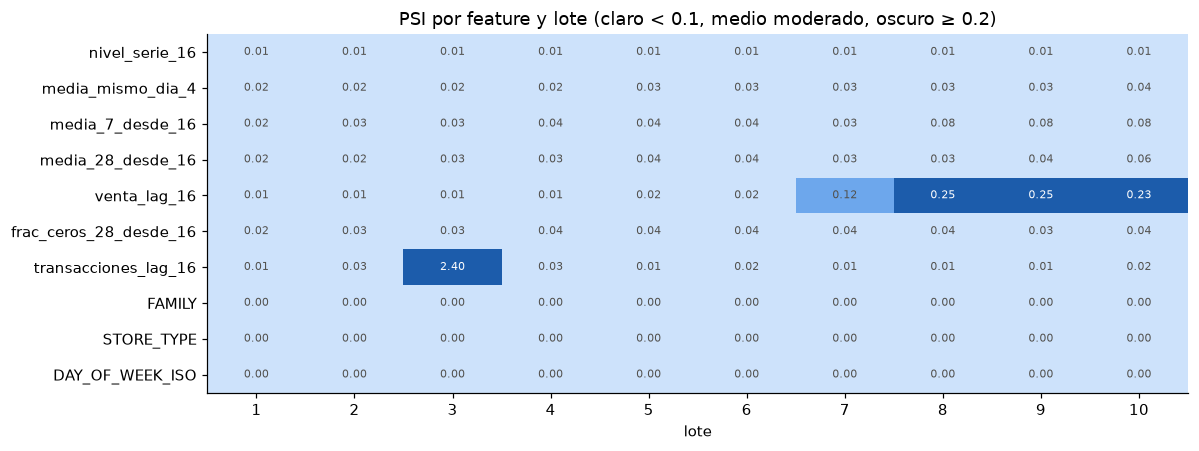

In [7]:
psi = pd.DataFrame({lote: p for lote, p in monitoreo['PSI'].items()}).T
psi = psi[NUMERICAS_VIGILADAS + CATEGORICAS_VIGILADAS]
print(f'PSI máximo en los lotes sin alterar (1, 2, 4): {psi.loc[[1, 2, 4]].max().max():.3f}')

figura, eje = plt.subplots(figsize=(11, 4.2))
mapa = ListedColormap(['#cde2fb', '#6da7ec', '#1c5cab'])
norma = BoundaryNorm([0, UMBRAL_PSI_MODERADO, UMBRAL_PSI, 100], mapa.N)
eje.imshow(psi.T, cmap=mapa, norm=norma, aspect='auto')
for (i, j), valor in np.ndenumerate(psi.T.to_numpy()):
    eje.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=7,
             color='white' if valor >= UMBRAL_PSI else '#52514e')
eje.set_xticks(range(len(psi)), psi.index)
eje.set_yticks(range(psi.shape[1]), psi.columns)
eje.grid(False)
eje.set(title=f'PSI por feature y lote (claro < {UMBRAL_PSI_MODERADO}, medio moderado, oscuro ≥ {UMBRAL_PSI})',
        xlabel='lote')
figura.tight_layout()
plt.show()

**Las pruebas estadísticas son el respaldo.** Kolmogorov-Smirnov (numéricas) y chi-cuadrado de homogeneidad
(categóricas) comparan cada lote con una muestra de 20.000 filas de entrenamiento
(`monitoreo/referencia_muestra.parquet`).

In [8]:
pruebas = monitoreo['PRUEBAS']
p_valores = pd.DataFrame({lote: {f: r['p_valor'] for f, r in p.items()} for lote, p in pruebas.items()}).T
estadistico_ks = pd.DataFrame({lote: {f: r['estadistico'] for f, r in p.items() if r['prueba'] == 'ks'}
                               for lote, p in pruebas.items()}).T[NUMERICAS_VIGILADAS]
resumen_pruebas = pd.DataFrame({
    'features con p < 0,01': (p_valores < 0.01).sum(axis=1),
    'de': p_valores.shape[1],
    'features con PSI ≥ 0,20': (psi >= UMBRAL_PSI).sum(axis=1)})
display(resumen_pruebas.T)
print('Estadístico D de Kolmogorov-Smirnov (distancia máxima entre las dos distribuciones acumuladas):')
estadistico_ks.round(3)

,1,2,3,4,5,6,7,8,9,10
"features con p < 0,01",7,7,7,7,7,7,7,7,7,7
de,10,10,10,10,10,10,10,10,10,10
"features con PSI ≥ 0,20",0,0,1,0,0,0,0,1,1,1


Estadístico D de Kolmogorov-Smirnov (distancia máxima entre las dos distribuciones acumuladas):


,nivel_serie_16,media_mismo_dia_4,media_7_desde_16,media_28_desde_16,venta_lag_16,frac_ceros_28_desde_16,transacciones_lag_16
1,0.032,0.044,0.054,0.047,0.051,0.060,0.032
2,0.034,0.046,0.056,0.053,0.049,0.064,0.041
3,0.031,0.052,0.055,0.056,0.049,0.060,0.512
4,0.033,0.054,0.061,0.060,0.055,0.062,0.037
5,0.035,0.059,0.062,0.062,0.057,0.065,0.032
6,0.035,0.059,0.065,0.065,0.059,0.068,0.058
7,0.034,0.062,0.052,0.063,0.085,0.066,0.045
8,0.032,0.058,0.077,0.061,0.096,0.062,0.034
9,0.030,0.053,0.068,0.060,0.092,0.062,0.038
10,0.028,0.055,0.064,0.060,0.084,0.062,0.048


**Por qué las pruebas no deciden la alerta.** Con 14.000 filas por lote, KS rechaza la igualdad de distribuciones
(p < 0,01) en las 7 numéricas de **todos** los lotes, incluidos los que no tienen ninguna alteración. Con ese tamaño,
cualquier diferencia mínima es estadísticamente significativa, aunque no tenga importancia práctica. Si la prueba
decidiera, cada lote dispararía una alerta.

**Para qué sirven:** el estadístico D sí distingue los cambios reales, igual que el PSI:

- `transacciones_lag_16` en el lote 3: D = 0,51, contra 0,03–0,06 en los demás lotes.
- `venta_lag_16` en los lotes 7 a 10: D de 0,085 a 0,096, contra 0,05 en los lotes normales.

D no depende de cómo se cortan las casillas, así que confirma que un PSI alto no es un efecto de los deciles. Las
categóricas (familia, tipo de tienda y día de la semana) no se movieron en ningún lote: la composición de lo que
llega es la misma; cambia cuánto se vende.

## 6. Deriva conceptual: el desempeño contra la validación cruzada

La métrica técnica de cada lote, cuando llega su target, se compara con la media y la desviación de la CV del
champion (5 pliegues de 16 días, `monitoreo/referencia_cv.json`). Se usa la **pérdida cuantil relativa** (pérdida
pinball 0,75 dividida por la venta media del lote): la pérdida absoluta sube con el volumen aunque el modelo acierte
igual en proporción, y un aumento de demanda la inflaría sin que el modelo empeore. Umbral: media de la CV más
2 desviaciones.

CV del champion: media 0.2162, desviación 0.0127 → umbral 0.2415


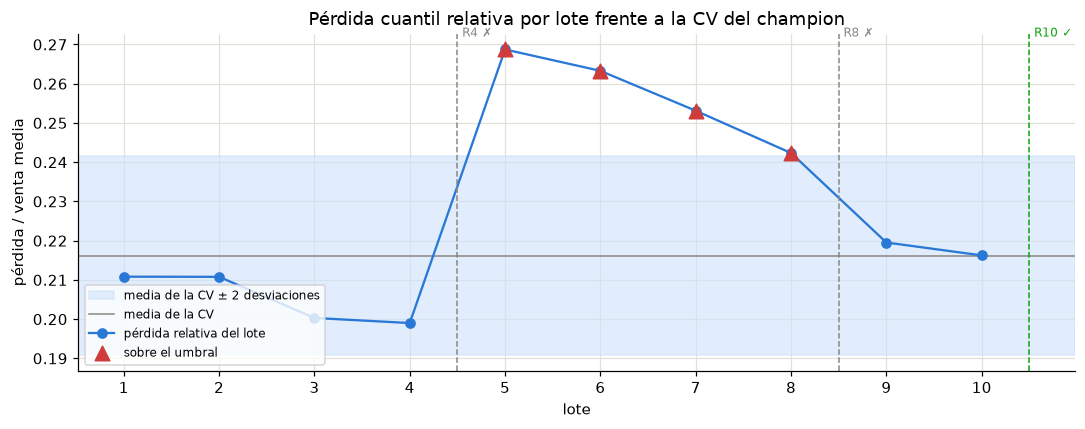

,psi_max,feature,entradas_cambian,perdida_relativa,desempeno_cae,diagnostico,conocido_en_paso,accion
LOTE,,,,,,,,
1,0.0243,frac_ceros_28_desde_16,False,0.2108,False,sin deriva,3,ninguna
2,0.0319,transacciones_lag_16,False,0.2108,False,sin deriva,4,ninguna
3,2.3992,transacciones_lag_16,True,0.2003,False,deriva de datos sin impacto,5,revisar la fuente y documentar; no se reentrena
4,0.0367,media_7_desde_16,False,0.1990,False,sin deriva,6,ninguna
5,0.0415,frac_ceros_28_desde_16,False,0.2687,True,deriva conceptual,7,"reentrenar con ventana reciente; si no mejora, revisar las features y el juicio humano"
6,0.0433,frac_ceros_28_desde_16,False,0.2633,True,deriva conceptual,8,"reentrenar con ventana reciente; si no mejora, revisar las features y el juicio humano"
7,0.1228,venta_lag_16,False,0.2531,True,deriva conceptual,9,"reentrenar con ventana reciente; si no mejora, revisar las features y el juicio humano"
8,0.2461,venta_lag_16,True,0.2423,True,deriva de datos con impacto,10,revisar la fuente y reentrenar con los lotes recientes (disparador por desempeño)
9,0.2486,venta_lag_16,True,0.2195,False,deriva de datos sin impacto,11,revisar la fuente y documentar; no se reentrena


In [9]:
cv = referencia_cv()['perdida_cuantil_relativa']
umbral_perdida = umbrales()['perdida_cuantil_relativa']
print(f"CV del champion: media {cv['media']:.4f}, desviación {cv['desviacion']:.4f} → umbral {umbral_perdida:.4f}")

figura, eje = plt.subplots(figsize=(10, 4))
eje.axhspan(cv['media'] - N_DESVIACIONES * cv['desviacion'], umbral_perdida, color='#cde2fb', alpha=0.6,
            label=f'media de la CV ± {N_DESVIACIONES} desviaciones')
eje.axhline(cv['media'], color=LINEA_BASE, linewidth=1, label='media de la CV')
perdida = monitoreo['PERDIDA_CUANTIL_RELATIVA']
eje.plot(perdida.index, perdida, marker='o', color=SERIE, label='pérdida relativa del lote')
sobre = perdida[perdida > umbral_perdida]
eje.scatter(sobre.index, sobre, marker='^', s=90, color=CRITICO, zorder=4, label='sobre el umbral')
marcar_reentrenamientos(eje, 0.272)
eje.set(title='Pérdida cuantil relativa por lote frente a la CV del champion', xlabel='lote',
        ylabel='pérdida / venta media', xticks=range(1, 11))
eje.legend(fontsize=8, loc='lower left')
figura.tight_layout()
plt.show()

diagnostico = pd.DataFrame({
    'psi_max': monitoreo['PSI_MAX'], 'feature': monitoreo['FEATURE_PSI_MAX'],
    'entradas_cambian': monitoreo['PSI_MAX'] > UMBRAL_PSI,
    'perdida_relativa': perdida, 'desempeno_cae': perdida > umbral_perdida,
    'diagnostico': monitoreo['DIAGNOSTICO'], 'conocido_en_paso': monitoreo['EVALUADO_EN_PASO']})
diagnostico['accion'] = [DIAGNOSTICOS[(e, d)][1] for e, d in zip(diagnostico['entradas_cambian'],
                                                                    diagnostico['desempeno_cae'])]
diagnostico.round(4)

**La tabla de la sección 6.2, con la acción de este proyecto y los lotes donde ocurrió:**

| Entradas | Desempeño | Diagnóstico | Acción | Lotes |
|---|---|---|---|---|
| Cambian | Se mantiene | Deriva de datos sin impacto | Revisar la fuente y documentar; **no se reentrena** | 3, 9, 10 |
| Cambian | Cae | Deriva de datos con impacto | Revisar la fuente y reentrenar con los lotes recientes (disparador por desempeño) | 8 |
| Estables | Cae | Deriva conceptual | Reentrenar con ventana reciente; si no mejora, revisar las features y el juicio humano | 5, 6, 7 |

- **Lote 3:** el PSI más alto de la simulación (2,40) con la pérdida más baja (0,200). La alerta de datos se
  disparó, pero no la de desempeño, y no hubo reentrenamiento. Es el caso que el enunciado pide: la deriva de datos
  sin caída de desempeño no reentrena.
- **Lotes 5 a 7:** la pérdida sale de la banda de la CV con un PSI por debajo de 0,20. Solo el target lo revela, dos
  semanas después de la predicción.
- **Lotes 9 y 10:** el PSI sigue alto, pero la pérdida volvió a la banda. El modelo se reajustó solo, porque sus
  entradas ya reflejan la demanda nueva (notebook 06, §3).

**El costo del retraso:** la deriva empezó en el lote 5 (predicho el 26/06), pero su pérdida se conoció en el paso 7
(10/07), y el reentrenamiento por desempeño necesitó un segundo lote (paso 8). Entre el cambio de demanda y el primer
challenger pasaron 3 semanas. Es el precio de esperar el target; un monitoreo solo por PSI habría visto el cambio
recién en el lote 8, una semana más tarde todavía.

## 7. Alertas

La plantilla de la sección 6.3, tal como está definida en `monitoreo/alertas.py`. Las alertas salen en el log de
Kestra (nivel WARN) y quedan en `PRODUCCION.ALERTAS`.

In [10]:
pd.DataFrame(tabla_alertas())[['alerta', 'metrica', 'umbral', 'ventana', 'severidad', 'recibe', 'accion']]

,alerta,metrica,umbral,ventana,severidad,recibe,accion
0,deriva_datos,PSI máximo de las features vigiladas,> 0.2,1 lote,alta,equipo de datos,"revisar la fuente; si el desempeño también cae, evaluar reentrenamiento"
1,deriva_datos_moderada,PSI máximo de las features vigiladas,0.1 a 0.2,1 lote,baja,equipo de datos,aviso: vigilar el lote siguiente
2,calidad_datos,faltantes en campos obligatorios + valores fuera de rango + categorías no vistas,> 0,1 lote,media,equipo de datos,revisar la fuente; la API ya rechazó esas filas (422) y no tienen pedido
3,desempeno,pérdida cuantil relativa (pérdida / venta media),> media CV + 2 desv.,1 lote con target,alta,equipo de ciencia de datos,diagnosticar la deriva; con 2 lotes seguidos se dispara el reentrenamiento
4,negocio,ahorro frente a la regla de negocio (%),< 0,1 lote con target,crítica,jefatura de operaciones y ciencia de datos,el modelo cuesta más que la regla: evaluar el interruptor de respaldo (criterio de ret...
5,latencia,latencia p95 del servicio (ms por petición),> 500,1 lote,media,equipo de plataforma,revisar recursos del contenedor; el lote puede repetirse
6,errores_servidor,tasa de errores 5xx,> 1%,1 lote,alta,equipo de plataforma,"revisar el servicio; si el modelo no carga, responde la regla de respaldo"
7,errores_cliente,tasa de errores 4xx,> 1%,1 lote,media,equipo de datos,revisar qué campos rechaza el contrato y la fuente que los produce


In [11]:
disparadas = alertas.pivot_table(index='LOTE', columns='ALERTA', values='VALOR', aggfunc='first')
disparadas = disparadas.reindex(range(1, 11))
print('Alertas disparadas por lote (valor que la disparó; vacío = no se disparó):')
display(disparadas.round(4))
sin_alterar = [1, 2, 4]
print('Lotes sin alterar con alguna alerta:', [k for k in sin_alterar if disparadas.loc[k].notna().any()] or 'ninguno')
alertas[['PASO', 'LOTE', 'ALERTA', 'VALOR', 'UMBRAL', 'SEVERIDAD', 'RECIBE', 'ACCION']].round(4)

Alertas disparadas por lote (valor que la disparó; vacío = no se disparó):


ALERTA,calidad_datos,deriva_datos,deriva_datos_moderada,desempeno,errores_cliente,latencia
LOTE,,,,,,
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,3.0,2.3992,NaN,NaN,0.2727,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,0.2687,NaN,1909.7032
6,NaN,NaN,NaN,0.2633,NaN,3181.3363
7,NaN,NaN,0.1228,0.2531,NaN,NaN
8,NaN,0.2461,NaN,0.2423,NaN,NaN
9,NaN,0.2486,NaN,NaN,NaN,852.1510


Lotes sin alterar con alguna alerta: ninguno


,PASO,LOTE,ALERTA,VALOR,UMBRAL,SEVERIDAD,RECIBE,ACCION
0,3,3,deriva_datos,2.3992,> 0.2,alta,equipo de datos,"revisar la fuente; si el desempeño también cae, evaluar reentrenamiento"
1,3,3,calidad_datos,3.0000,> 0,media,equipo de datos,revisar la fuente; la API ya rechazó esas filas (422) y no tienen pedido
2,3,3,errores_cliente,0.2727,> 1%,media,equipo de datos,revisar qué campos rechaza el contrato y la fuente que los produce
3,5,5,latencia,1909.7032,> 500,media,equipo de plataforma,revisar recursos del contenedor; el lote puede repetirse
4,6,6,latencia,3181.3363,> 500,media,equipo de plataforma,revisar recursos del contenedor; el lote puede repetirse
5,7,5,desempeno,0.2687,> media CV + 2 desv.,alta,equipo de ciencia de datos,diagnosticar la deriva; con 2 lotes seguidos se dispara el reentrenamiento
6,7,7,deriva_datos_moderada,0.1228,0.1 a 0.2,baja,equipo de datos,aviso: vigilar el lote siguiente
7,8,6,desempeno,0.2633,> media CV + 2 desv.,alta,equipo de ciencia de datos,diagnosticar la deriva; con 2 lotes seguidos se dispara el reentrenamiento
8,8,8,deriva_datos,0.2461,> 0.2,alta,equipo de datos,"revisar la fuente; si el desempeño también cae, evaluar reentrenamiento"
9,9,7,desempeno,0.2531,> media CV + 2 desv.,alta,equipo de ciencia de datos,diagnosticar la deriva; con 2 lotes seguidos se dispara el reentrenamiento


- **Los lotes sin alterar (1, 2 y 4) no dispararon ninguna alerta.**
- **El lote con deriva inducida (3) disparó las tres alertas que le correspondían** el mismo día de la predicción:
  `deriva_datos` (PSI 2,40), `calidad_datos` (3 filas) y `errores_cliente` (27 % de las peticiones).
- **El aumento de demanda disparó** `desempeno` en los lotes 5 a 8 (cada una, dos pasos después de su lote), el aviso
  moderado en el lote 7 y `deriva_datos` en los lotes 8 a 10. Son alertas verdaderas.
- **Las tres alertas de `latencia` (lotes 5, 6 y 9) son falsas alarmas**, documentadas en §2.
- **La alerta `negocio` (ahorro < 0) no se disparó nunca**: el modelo le ganó a la regla en todos los lotes.

## 8. Del monitoreo al reentrenamiento

**Disparadores (sección 7.1, `monitoreo/alertas.py`):**

- **Por desempeño:** la pérdida relativa supera la media de la CV más 2 desviaciones en 2 lotes
  consecutivos con target, contados desde el último reentrenamiento. Sin esa última condición, una deriva que dura
  dispararía un reentrenamiento en cada paso.
- **Por calendario:** cada 4 pasos con lote nuevo, aunque no haya alertas.
- **La deriva de datos sin caída de desempeño no dispara el reentrenamiento** (lote 3), y el reentrenamiento solo usa
  lotes cuyo target ya llegó.

In [12]:
eventos = []
for paso in range(1, 13):
    con_target = monitoreo.index[monitoreo['EVALUADO_EN_PASO'] == paso].tolist()
    alerta_desempeno = alertas[(alertas['PASO'] == paso) & (alertas['ALERTA'] == 'desempeno')]['LOTE'].tolist()
    r = reentrenamientos[reentrenamientos['PASO'] == paso]
    eventos.append({'paso': paso, 'llega el target de': ', '.join(map(str, con_target)) or '-',
                    'alerta de desempeño en': ', '.join(map(str, alerta_desempeno)) or '-',
                    'reentrenamiento': r['MOTIVO'].iloc[0] if len(r) else '-',
                    'decisión': (f"v{r['VERSION_CHALLENGER'].iloc[0]} {r['DECISION'].iloc[0]} "
                                 f"({r['DIFERENCIA_AHORRO_PP'].iloc[0]:+.2f} pp)") if len(r) else '-'})
pd.DataFrame(eventos).set_index('paso')

,llega el target de,alerta de desempeño en,reentrenamiento,decisión
paso,,,,
1,-,-,-,-
2,-,-,-,-
3,1,-,-,-
4,2,-,calendario: cada 4 lotes (paso 4),v5 rechazado (+2.28 pp)
5,3,-,-,-
6,4,-,-,-
7,5,5,-,-
8,6,6,desempeño: pérdida relativa > 0.2415 en los lotes 5 y 6; calendario: cada 4 lotes (pas...,v6 rechazado (+2.04 pp)
9,7,7,-,-


**El ciclo completo sobre el lote con deriva (sección 7.4)** quedó registrado dos veces:

1. **Paso 8:** alerta de desempeño en los lotes 5 y 6 (deriva conceptual) → `reentrenamiento.yml` entrena el
   challenger v6 con el histórico más los lotes 1 a 5 → lo registra en MLflow con `fase=reentrenamiento`, el motivo y
   el alias `challenger` → compara champion y challenger en el lote 6, que ninguno vio → la regla recomienda mantener
   (+2,04 pp < 2,78 pp) → pausa → una persona **rechaza**, con el motivo "el challenger solo incluye un lote con la
   deriva" → el champion queda intacto.
2. **Paso 10:** alerta en los lotes 7 y 8 → challenger v7 con los lotes 1 a 7 → comparación en el lote 8 (+4,13 pp)
   → la regla recomienda promover → en la pausa se usó por error *Restart* en lugar de *Resume*: el flujo se reanudó
   sin el formulario y, por diseño, lo registró como rechazo → la persona responsable aplicó la aprobación a mano con
   el mismo paso del flujo (`python -m src.reentrenar decidir 10 si`), con su motivo → el alias `champion` pasa a la
   v7 y la API la carga sin reconstruir la imagen. El incidente queda en `PRODUCCION.REENTRENAMIENTOS` y muestra que
   la pausa falla hacia el lado seguro: sin aprobación explícita, el modelo no cambia.

El ciclo con el formulario de aprobación completo es el del paso 12 (la demostración del video, v8), hecho después
del rollback a la v3: por eso la v8 se comparó contra la v3. El paso 4 es el disparador por calendario, sin alerta;
su pausa también se reanudó sin el formulario y quedó como rechazo por defecto, que coincide con la recomendación de
la regla. La versión 4 del registro es una corrida de prueba del flujo, anterior a la simulación, sin decisión. El efecto de cada decisión fuera de su lote de evaluación se
mide en el notebook 06 (§5): el rechazo del paso 8 costó entre 2 y 3,5 pp de ahorro en los lotes 9 y 10, y la
aprobación del paso 10 se confirma en los tres lotes que la v7 no vio.

## 9. Ética operativa y criterios de retirada

### 9.1 Desempeño por subgrupo

Se calculan la métrica técnica (pérdida relativa), la métrica de negocio (ahorro frente a la regla), la tasa de cada
decisión y las dos caras del error (cobertura y merma) por tres subgrupos:

- **Familia de producto** (9 familias de perecederos): el subgrupo del negocio; el stock de seguridad de la regla ya
  es por familia.
- **Tipo de tienda** (A a E): formatos distintos, con volúmenes distintos.
- **Región** (provincia de la tienda, de `GOLD.DIM_STORE`): las personas afectadas por un faltante son los clientes de
  esa zona, y en provincias con pocas tiendas no tienen dónde más comprar.

In [13]:
filas = consultar(f'''
    SELECT l.*, p.PEDIDO, p.DECISION, t.UNIT_SALES_TARGET, s.STATE, s.CITY
    FROM {ESQUEMA}.PREDICCIONES p
    JOIN {ESQUEMA}.LOTES l ON l.STORE_NBR = p.STORE_NBR AND l.ITEM_NBR = p.ITEM_NBR AND l.DATE = p.DATE
                          AND l.DEFECTO IS NULL
    JOIN {ESQUEMA}.LOTES_TARGET t ON t.STORE_NBR = p.STORE_NBR AND t.ITEM_NBR = p.ITEM_NBR AND t.DATE = p.DATE
    JOIN (SELECT DISTINCT STORE_NBR, STATE, CITY FROM PSET2_DB.GOLD.DIM_STORE) s ON s.STORE_NBR = p.STORE_NBR''',
                  'PSET4_NB07').rename(columns=lambda c: c.lower() if c.lower() in COLUMNAS_X else c)
X = tipos_firma(filas[COLUMNAS_X])
filas['PEDIDO_REGLA'] = ReglaRespaldo.cargar('../api/respaldo.json').predict(X)
filas['FAMILY'], filas['STORE_TYPE'] = X['FAMILY'], X['STORE_TYPE']
print(f'{len(filas):,} predicciones con target, {filas["STORE_NBR"].nunique()} tiendas en '
      f'{filas["STATE"].nunique()} provincias')


def por_subgrupo(columna):
    def medir(g):
        y, pedido = g['UNIT_SALES_TARGET'].to_numpy(), g['PEDIDO'].to_numpy()
        modelo, regla = resultado_negocio(y, pedido), resultado_negocio(y, g['PEDIDO_REGLA'].to_numpy())
        perdida = np.mean(np.maximum(0.75 * (y - pedido), 0.25 * (pedido - y)))
        return pd.Series({'filas': len(g), 'tiendas': g['STORE_NBR'].nunique(), 'venta_media': y.mean(),
                          'perdida_relativa': perdida / y.mean(),
                          'ahorro_vs_regla_pct': 100 * (1 - modelo['costo'] / regla['costo']),
                          'tasa_reponer': (g['DECISION'] == 'reponer').mean(),
                          'cobertura': modelo['cobertura'], 'cobertura_regla': regla['cobertura'],
                          'merma': modelo['merma'], 'merma_regla': regla['merma']})
    return filas.groupby(columna).apply(medir, include_groups=False).sort_values('filas', ascending=False)


familia = por_subgrupo('FAMILY')
familia.round(3)

139,981 predicciones con target, 54 tiendas en 16 provincias


,filas,tiendas,venta_media,perdida_relativa,ahorro_vs_regla_pct,tasa_reponer,cobertura,cobertura_regla,merma,merma_regla
FAMILY,,,,,,,,,,
PRODUCE,41914.0,54.0,14.365,0.215,27.421,0.875,0.801,0.691,0.246,0.271
DAIRY,39130.0,54.0,6.073,0.249,18.206,0.929,0.785,0.707,0.309,0.324
BREAD/BAKERY,17990.0,53.0,8.061,0.233,15.945,0.935,0.784,0.726,0.268,0.284
DELI,14840.0,53.0,5.283,0.263,16.663,0.949,0.766,0.690,0.314,0.325
MEATS,7977.0,44.0,12.335,0.214,23.017,0.862,0.790,0.706,0.220,0.244
POULTRY,7700.0,45.0,15.876,0.254,23.891,0.843,0.754,0.643,0.269,0.291
EGGS,5110.0,39.0,9.370,0.240,16.107,0.958,0.757,0.700,0.234,0.260
PREPARED FOODS,4340.0,38.0,6.335,0.307,-7.407,0.723,0.671,0.724,0.265,0.303
SEAFOOD,980.0,13.0,3.789,0.277,17.440,0.820,0.790,0.732,0.378,0.424


In [14]:
tipo_tienda = por_subgrupo('STORE_TYPE')
display(tipo_tienda.round(3))
region = por_subgrupo('STATE')
region.round(3)

,filas,tiendas,venta_media,perdida_relativa,ahorro_vs_regla_pct,tasa_reponer,cobertura,cobertura_regla,merma,merma_regla
STORE_TYPE,,,,,,,,,,
D,51170.0,18.0,8.632,0.230,20.263,0.910,0.794,0.717,0.277,0.299
A,29540.0,9.0,18.566,0.209,25.375,0.958,0.800,0.686,0.227,0.207
C,29187.0,15.0,4.851,0.282,18.732,0.848,0.743,0.700,0.324,0.411
B,19444.0,8.0,8.249,0.245,22.688,0.884,0.775,0.685,0.281,0.319
E,10640.0,4.0,6.653,0.291,19.338,0.875,0.722,0.646,0.313,0.370


,filas,tiendas,venta_media,perdida_relativa,ahorro_vs_regla_pct,tasa_reponer,cobertura,cobertura_regla,merma,merma_regla
STATE,,,,,,,,,,
Pichincha,57260.0,19.0,14.170,0.211,24.420,0.928,0.803,0.698,0.241,0.233
Guayas,26312.0,11.0,7.481,0.257,21.508,0.871,0.757,0.678,0.285,0.338
Manabi,8330.0,3.0,8.543,0.231,26.964,0.879,0.782,0.679,0.257,0.310
Azuay,7280.0,3.0,9.156,0.248,19.311,0.942,0.771,0.687,0.284,0.297
Santo Domingo de los Tsachilas,7140.0,3.0,4.867,0.293,18.461,0.878,0.737,0.679,0.342,0.412
Tungurahua,5250.0,2.0,6.812,0.249,14.907,0.880,0.779,0.728,0.301,0.328
El Oro,5037.0,2.0,6.207,0.271,13.903,0.932,0.752,0.715,0.311,0.359
Los Rios,4822.0,2.0,6.409,0.265,17.143,0.843,0.747,0.703,0.287,0.354
Santa Elena,3080.0,1.0,3.813,0.336,16.565,0.894,0.709,0.665,0.399,0.477


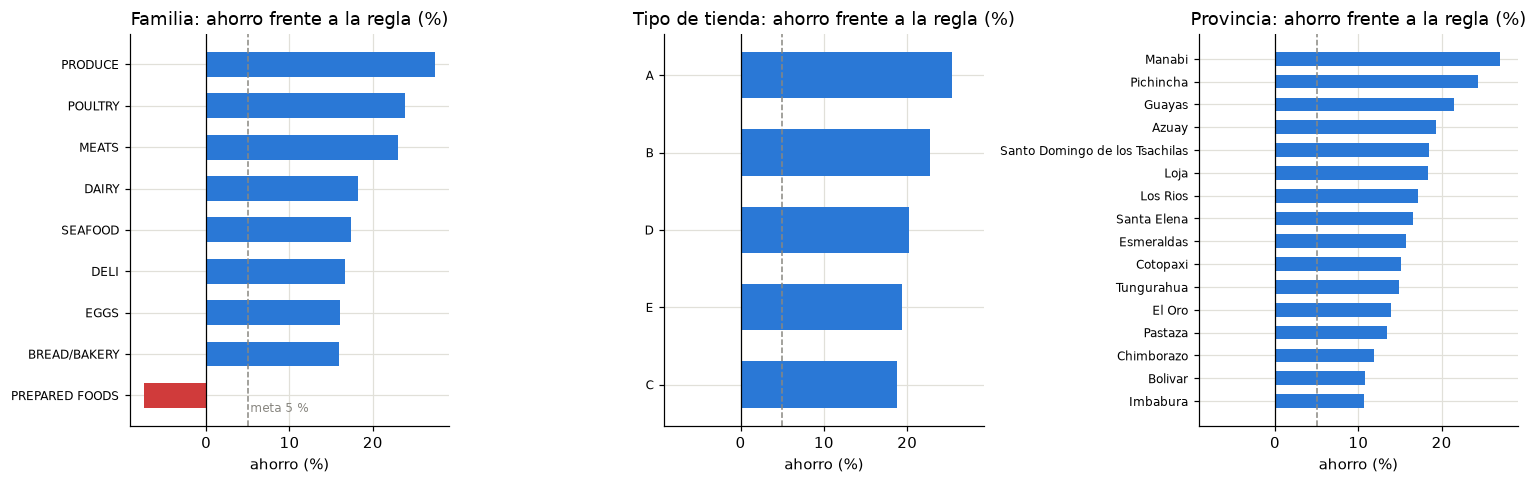

,ahorro mínimo en un lote (%),lotes con algún subgrupo bajo 0 %,subgrupo que más veces queda último
subgrupo,,,
familia,-18.21,9,PREPARED FOODS
provincia,-4.15,1,Bolivar
tipo de tienda,12.12,0,C


In [15]:
figura, ejes = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True)
for eje, (titulo, tabla) in zip(ejes, [('Familia', familia), ('Tipo de tienda', tipo_tienda), ('Provincia', region)]):
    orden = tabla.sort_values('ahorro_vs_regla_pct')
    colores = [CRITICO if v < 0 else SERIE for v in orden['ahorro_vs_regla_pct']]
    eje.barh(orden.index, orden['ahorro_vs_regla_pct'], color=colores, height=0.6)
    eje.axvline(0, color='black', linewidth=0.8)
    eje.axvline(5, color=LINEA_BASE, linestyle='--', linewidth=1)
    eje.set(title=f'{titulo}: ahorro frente a la regla (%)', xlabel='ahorro (%)')
    eje.tick_params(axis='y', labelsize=8)
ejes[0].text(5.3, -0.4, 'meta 5 %', color=LINEA_BASE, fontsize=8)
figura.tight_layout()
plt.show()

# Estabilidad: el subgrupo con menor ahorro en cada lote.
peor = []
for columna, nombre in [('FAMILY', 'familia'), ('STORE_TYPE', 'tipo de tienda'), ('STATE', 'provincia')]:
    for lote, g in filas.groupby('LOTE'):
        costo = g.groupby(columna).apply(lambda s: pd.Series({
            'modelo': resultado_negocio(s['UNIT_SALES_TARGET'], s['PEDIDO'])['costo'],
            'regla': resultado_negocio(s['UNIT_SALES_TARGET'], s['PEDIDO_REGLA'])['costo']}), include_groups=False)
        ahorro = 100 * (1 - costo['modelo'] / costo['regla'])
        peor.append({'subgrupo': nombre, 'lote': lote, 'peor': ahorro.idxmin(), 'ahorro_min_pct': ahorro.min()})
peor = pd.DataFrame(peor)
peor.groupby('subgrupo').apply(lambda g: pd.Series({
    'ahorro mínimo en un lote (%)': g['ahorro_min_pct'].min(),
    'lotes con algún subgrupo bajo 0 %': int((g['ahorro_min_pct'] < 0).sum()),
    'subgrupo que más veces queda último': g['peor'].mode().iloc[0]}), include_groups=False).round(2)

In [16]:
# La familia con ahorro negativo, lote por lote.
preparados = filas[filas['FAMILY'] == 'PREPARED FOODS']


def detalle(g):
    m = resultado_negocio(g['UNIT_SALES_TARGET'], g['PEDIDO'])
    r = resultado_negocio(g['UNIT_SALES_TARGET'], g['PEDIDO_REGLA'])
    return pd.Series({'ahorro_vs_regla_pct': 100 * (1 - m['costo'] / r['costo']),
                      'cobertura': m['cobertura'], 'cobertura_regla': r['cobertura'],
                      'pedido_medio': g['PEDIDO'].mean(), 'pedido_regla_medio': g['PEDIDO_REGLA'].mean(),
                      'venta_media': g['UNIT_SALES_TARGET'].mean(),
                      'dias_sin_venta': (g['UNIT_SALES_TARGET'] == 0).mean(),
                      'tasa_reponer': (g['DECISION'] == 'reponer').mean()})


print(f"PREPARED FOODS: {preparados.groupby(['STORE_NBR', 'ITEM_NBR']).ngroups} series de "
      f"{preparados['ITEM_NBR'].nunique()} productos, {len(preparados) / len(filas):.1%} de las predicciones")
preparados.groupby('LOTE').apply(detalle, include_groups=False).round(3)

PREPARED FOODS: 62 series de 21 productos, 3.1% de las predicciones


,ahorro_vs_regla_pct,cobertura,cobertura_regla,pedido_medio,pedido_regla_medio,venta_media,dias_sin_venta,tasa_reponer
LOTE,,,,,,,,
1,-1.739,0.764,0.829,5.153,6.337,4.869,0.641,0.578
2,-8.184,0.772,0.849,5.167,6.254,4.683,0.650,0.620
3,-14.056,0.738,0.820,5.234,6.182,4.930,0.650,0.622
4,-18.205,0.739,0.825,5.450,6.242,4.828,0.622,0.684
5,-15.747,0.523,0.613,5.221,6.203,7.257,0.636,0.719
6,-13.489,0.616,0.690,5.347,6.217,6.512,0.611,0.788
7,-1.432,0.618,0.653,5.473,6.366,7.299,0.613,0.737
8,9.443,0.676,0.662,6.321,6.795,7.621,0.631,0.735
9,-3.394,0.664,0.682,7.045,7.268,7.639,0.641,0.869


**Familia: PREPARED FOODS es la excepción.** Es la única familia donde el modelo cuesta más que la regla en el
total de los 10 lotes (−7,4 %), y lo hace en 9 de los 10 lotes (tabla siguiente). Pide menos que la regla y cubre
menos demanda (67 % contra 72 %). Las otras 8 familias ahorran entre 16 y 27 %, por encima de la meta de 5 %.

**Tipo de tienda y provincia: diferencias aceptables.** Todos los tipos de tienda ahorran entre 19 y 25 % y ninguno
queda bajo 0 % en ningún lote. Las provincias ahorran entre 11 y 27 %; solo Bolívar (una tienda) queda bajo 0 % en un
lote (−4,2 %). Las provincias con menos tiendas tienen menos ahorro y menos cobertura, pero el modelo sigue cubriendo
más demanda que la regla en casi todas (Pastaza es la excepción: 67,3 % contra 70,1 %).

**Por qué falla PREPARED FOODS (hipótesis).** Es la familia más intermitente: más del 60 % de los días de cada
serie no tiene venta. El modelo usa un solo cuantil 0,75 para todas las familias, entrenado sobre todas las series;
en una familia con tantos ceros, ese cuantil queda bajo y el modelo decide `no reponer` más seguido. La regla, en
cambio, tiene un stock de seguridad propio para cada familia y pide más.

**¿Es aceptable?** Para el negocio, sí en el total: la familia es el 3 % de las predicciones y el ahorro global es de
22,3 %. Para las personas afectadas, no: los clientes que buscan comida preparada la encuentran menos que con el
proceso actual, y ese faltante es concentrado y sistemático, no aleatorio. Por eso se activa el criterio de retirada
3 de §9.3: esa familia vuelve a la regla hasta que un reentrenamiento la corrija (por ejemplo, con un cuantil
calibrado por familia o un modelo propio para la demanda intermitente).

### 9.2 Quién asume cada error

Con Co:Cu = 1:3 el modelo pide el cuantil 0,75 de la demanda: se equivoca hacia arriba a propósito. Cada error tiene
un responsable distinto:

In [17]:
errores = filas.assign(
    sobrante_modelo=np.maximum(filas['PEDIDO'] - filas['UNIT_SALES_TARGET'], 0),
    faltante_modelo=np.maximum(filas['UNIT_SALES_TARGET'] - filas['PEDIDO'], 0),
    sobrante_regla=np.maximum(filas['PEDIDO_REGLA'] - filas['UNIT_SALES_TARGET'], 0),
    faltante_regla=np.maximum(filas['UNIT_SALES_TARGET'] - filas['PEDIDO_REGLA'], 0),
).groupby('LOTE')[['sobrante_modelo', 'sobrante_regla', 'faltante_modelo', 'faltante_regla']].sum()
errores['venta'] = filas.groupby('LOTE')['UNIT_SALES_TARGET'].sum()
total = errores.sum()
print(f"Los 10 lotes, en unidades: el modelo deja {total['sobrante_modelo']:,.0f} sobrantes y "
      f"{total['faltante_modelo']:,.0f} faltantes; la regla, {total['sobrante_regla']:,.0f} y "
      f"{total['faltante_regla']:,.0f}. Venta total: {total['venta']:,.0f}.")
errores.round(0)

Los 10 lotes, en unidades: el modelo deja 385,524 sobrantes y 292,945 faltantes; la regla, 380,256 y 415,334. Venta total: 1,362,892.


,sobrante_modelo,sobrante_regla,faltante_modelo,faltante_regla,venta
LOTE,,,,,
1,45740.0,43934.0,14876.0,25169.0,107161.0
2,45515.0,43496.0,14591.0,24295.0,105897.0
3,41973.0,42430.0,14680.0,24592.0,107352.0
4,47614.0,42482.0,13211.0,27155.0,109603.0
5,27293.0,27955.0,50373.0,68766.0,165983.0
6,25747.0,30058.0,45868.0,59594.0,155118.0
7,28560.0,30482.0,42288.0,55283.0,153512.0
8,33749.0,36102.0,37506.0,47942.0,150897.0
9,41042.0,36116.0,33521.0,48710.0,161261.0


| Error | Qué pasa | Quién lo asume | Magnitud en la simulación |
|---|---|---|---|
| **Sobreestimación** (pedido > venta) | El perecedero que sobra se pierde al final del día: merma. | La tienda y su área de perecederos (el costo del producto desechado), y finanzas en el margen. | 385.524 unidades con el modelo, 380.256 con la regla: casi lo mismo. |
| **Subestimación** (pedido < venta) | El cliente no encuentra el producto: venta perdida. | El cliente, primero (sobre todo donde no hay otra tienda cerca, y en productos de primera necesidad como lácteos, huevos y pan), y la tienda, que pierde la venta y la confianza. | 292.945 unidades con el modelo contra 415.334 con la regla: **122.389 faltantes menos** (−29 %). |

El escenario Co:Cu = 1:3 protege a propósito al que más pierde: un faltante pesa el triple que un sobrante. El
resultado es el buscado: el modelo deja prácticamente la misma merma que la regla y reduce los faltantes en casi un
tercio. La excepción es PREPARED FOODS, donde el modelo traslada el error hacia los faltantes, es decir, hacia los
clientes.

### 9.3 Criterios de retirada

Condiciones observables bajo las cuales el modelo se ajusta o se retira, cada una con su métrica, umbral y respuesta.
La tabla evalúa cada criterio con lo que pasó en la simulación.

In [18]:
ahorro = monitoreo['AHORRO_VS_REGLA_PCT']
cobertura_familia = (filas.groupby(['LOTE', 'FAMILY'])
                     .apply(lambda g: resultado_negocio(g['UNIT_SALES_TARGET'], g['PEDIDO'])['cobertura']
                            - resultado_negocio(g['UNIT_SALES_TARGET'], g['PEDIDO_REGLA'])['cobertura'],
                            include_groups=False).unstack())


def max_consecutivos(serie):
    mejor = actual = 0
    for valor in serie:
        actual = actual + 1 if valor else 0
        mejor = max(mejor, actual)
    return mejor


rechazo = (monitoreo['FILAS_LOTE'] - monitoreo['PRODUCTOS']) / monitoreo['FILAS_LOTE']
criterios = pd.DataFrame([
    {'criterio': '1. El modelo cuesta más que la regla',
     'metrica': 'ahorro frente a la regla (%) por lote',
     'umbral': '< 0 en 2 lotes seguidos, aun después de reentrenar',
     'respuesta': 'interruptor de respaldo (la API responde con la regla) y revisión del modelo',
     'observado': f'mínimo {ahorro.min():.1f} %; lotes bajo 0: {int((ahorro < 0).sum())}',
     'se_activo': bool(max_consecutivos(ahorro < 0) >= 2)},
    {'criterio': '2. El reentrenamiento no corrige la caída',
     'metrica': 'pérdida relativa por lote',
     'umbral': f'> media CV + 2σ ({umbral_perdida:.4f}) en 2 lotes seguidos después de un reentrenamiento aprobado',
     'respuesta': 'retirar el modelo: respaldo y revisión de features y del juicio humano',
     'observado': 'el único aprobado (paso 10) llegó después del último lote: sin lotes para evaluarlo',
     'se_activo': False},
    {'criterio': '3. Un subgrupo queda peor que con la regla',
     'metrica': 'cobertura del modelo menos la de la regla, por familia y lote',
     'umbral': '< 0 en una familia durante 2 lotes seguidos',
     'respuesta': 'ajuste: esa familia vuelve a la regla (respaldo por familia) hasta reentrenar',
     'observado': f'diferencia mínima {cobertura_familia.min().min() * 100:+.1f} pp '
                  f'({cobertura_familia.min().idxmin()})',
     'se_activo': bool(max(max_consecutivos(cobertura_familia[c] < 0) for c in cobertura_familia) >= 2)},
    {'criterio': '4. El servicio no puede usar el modelo',
     'metrica': 'tasa de errores 5xx / modelo sin cargar',
     'umbral': '> 1 % de las peticiones de un lote, o el modelo no carga',
     'respuesta': 'respaldo automático (ya implementado en la API) y alerta a plataforma',
     'observado': f'5xx máximo {monitoreo["TASA_ERRORES_SERVIDOR"].max():.0%}',
     'se_activo': bool((monitoreo['TASA_ERRORES_SERVIDOR'] > 0.01).any())},
    {'criterio': '5. La fuente deja de cumplir el contrato',
     'metrica': 'filas rechazadas (422) / filas del lote',
     'umbral': '> 1 % de las filas de un lote',
     'respuesta': 'detener el lote, pedir esas filas a la regla y revisar la fuente antes de reenviar',
     'observado': f'máximo {rechazo.max():.3%} (lote {rechazo.idxmax()})',
     'se_activo': bool((rechazo > 0.01).any())},
])
criterios

,criterio,metrica,umbral,respuesta,observado,se_activo
0,1. El modelo cuesta más que la regla,ahorro frente a la regla (%) por lote,"< 0 en 2 lotes seguidos, aun después de reentrenar",interruptor de respaldo (la API responde con la regla) y revisión del modelo,mínimo 15.0 %; lotes bajo 0: 0,False
1,2. El reentrenamiento no corrige la caída,pérdida relativa por lote,> media CV + 2σ (0.2415) en 2 lotes seguidos después de un reentrenamiento aprobado,retirar el modelo: respaldo y revisión de features y del juicio humano,el único aprobado (paso 10) llegó después del último lote: sin lotes para evaluarlo,False
2,3. Un subgrupo queda peor que con la regla,"cobertura del modelo menos la de la regla, por familia y lote",< 0 en una familia durante 2 lotes seguidos,ajuste: esa familia vuelve a la regla (respaldo por familia) hasta reentrenar,diferencia mínima -8.9 pp (PREPARED FOODS),True
3,4. El servicio no puede usar el modelo,tasa de errores 5xx / modelo sin cargar,"> 1 % de las peticiones de un lote, o el modelo no carga",respaldo automático (ya implementado en la API) y alerta a plataforma,5xx máximo 0%,False
4,5. La fuente deja de cumplir el contrato,filas rechazadas (422) / filas del lote,> 1 % de las filas de un lote,"detener el lote, pedir esas filas a la regla y revisar la fuente antes de reenviar",máximo 0.021% (lote 3),False


- **El criterio 3 se activó:** PREPARED FOODS tuvo menos cobertura que la regla en lotes seguidos. La respuesta
  definida es un ajuste parcial: esa familia vuelve a la regla de respaldo mientras el resto sigue con el modelo.
  La API hoy tiene un interruptor global; el respaldo por familia es el primer cambio pendiente.
- **Los criterios 1, 4 y 5 no se activaron.** El lote 3 rechazó el 0,02 % de sus filas, muy por debajo del 1 %: la
  API descartó las filas defectuosas sin detener el pedido.
- **El criterio 2 no se pudo evaluar:** el único reentrenamiento aprobado de la simulación llegó después del último
  lote. Quedaría a prueba en los lotes siguientes, con la v7 como champion.

### 9.4 Interruptor de respaldo

Implementado de dos formas en la API (`api/main.py`):

- **Variable de entorno** `MODO_RESPALDO=true`: la API arranca respondiendo con la regla.
- **Ruta protegida** `POST /respaldo` (token de administrador en `x-token-admin`): lo enciende o lo apaga en caliente,
  con un motivo, sin reiniciar el servicio.

Con el interruptor encendido, cada respuesta trae `respaldo: true`, el motivo y `version_modelo: null`, y
`GET /salud` reporta el estado `degradado`. La regla (`api/respaldo.json`) se carga al arrancar, así que también
responde si MLflow no está disponible. El video de demostración muestra el interruptor encendido sobre el servicio
en Docker; los dos interruptores, el rechazo sin token (401) y el registro de las predicciones hechas con la regla
quedan cubiertos por las pruebas de `tests/test_respaldo.py`.

### 9.5 Supervisión humana

**Lo definido en el PSet 1:** "el departamento de compras revisaría el pronóstico y sus restricciones antes de actuar".

**Ese juicio ya no es adecuado tal como estaba, y cambia de lugar.** Revisar cada pronóstico antes de actuar
significa 14.000 pedidos por semana, unos 260 por tienda: nadie los revisaría con atención, y la revisión se
volvería una firma automática. El comportamiento del modelo tampoco lo justifica: le ganó a la regla en todos los lotes
y en todos los tipos de tienda.

**El juicio humano nuevo actúa en tres puntos, donde una persona sí aporta:**

1. **Aprobar o rechazar cada cambio de modelo** (la pausa de `reentrenamiento.yml`), con un motivo registrado. En la
   simulación las tres decisiones coincidieron con la regla, pero solo la del paso 8 se tomó con el formulario: allí
   el motivo agregó información que la regla no tenía (el challenger solo había visto un lote de la deriva). Los pasos
   4 y 10 se reanudaron sin el formulario, lo que se registró como rechazo; en el paso 10 la aprobación se aplicó
   después a mano. La lección operativa: la pausa protege contra un clic equivocado, pero la persona que aprueba
   necesita saber que debe usar *Resume* con el formulario (README, §4.7).
2. **Revisar las excepciones de cada semana:** los pedidos que se apartan mucho de la regla (más de 5 unidades y más
   del doble de diferencia). Son entre 2 y 4 % de los pedidos, unos 5 a 10 por tienda y semana (tabla siguiente), una
   carga que compras sí puede revisar antes de enviar el pedido.
3. **Decidir el interruptor de respaldo**, global o por familia, cuando se activa un criterio de retirada, como el de
   PREPARED FOODS.

In [19]:
# Carga de trabajo de una revisión por excepción: pedidos que se apartan mucho de la regla.
filas['excepcion'] = ((filas['PEDIDO'] - filas['PEDIDO_REGLA']).abs() > np.maximum(5, filas['PEDIDO_REGLA']))
excepciones = filas.groupby('LOTE').agg(pedidos=('PEDIDO', 'size'), excepciones=('excepcion', 'sum'))
excepciones['por_tienda_y_semana'] = excepciones['excepciones'] / filas['STORE_NBR'].nunique()
excepciones['pct'] = 100 * excepciones['excepciones'] / excepciones['pedidos']
excepciones.round(2)

,pedidos,excepciones,por_tienda_y_semana,pct
LOTE,,,,
1,13983,366,6.78,2.62
2,13998,382,7.07,2.73
3,14000,330,6.11,2.36
4,14000,560,10.37,4.00
5,14000,409,7.57,2.92
6,14000,323,5.98,2.31
7,14000,311,5.76,2.22
8,14000,295,5.46,2.11
9,14000,353,6.54,2.52


Las excepciones no crecen durante la deriva (2,0 a 2,9 % en los lotes 5 a 10): el modelo y la regla se mueven
juntos cuando cambia la demanda, así que la carga de revisión se mantiene estable. El lote 4 tiene más excepciones
(4,0 %) sin ninguna alteración. Es la semana del cierre de junio (fin de mes y día de pago); es probable que ahí el
modelo, que conoce el calendario, se aparte más de la media de 28 días, que no lo conoce.

## 10. Conclusiones

1. **El monitoreo distinguió los dos tipos de deriva.** El lote 3 (fuente alterada) disparó las alertas de datos el
   mismo día y no disparó reentrenamiento, porque su desempeño no cayó. El aumento de demanda apareció primero como
   deriva conceptual (lotes 5–7, solo visible con el target) y después como deriva de datos (lotes 8–10).
2. **Ningún lote sin alterar disparó alertas.** Las únicas falsas alarmas fueron de latencia (lotes 5, 6 y 9): una
   petición lenta entre 7. Se corrigen alertando con la mediana y con la duración del lote.
3. **El PSI decide y las pruebas KS y chi-cuadrado lo respaldan.** Con 14.000 filas, KS rechaza en todos los lotes;
   su estadístico D, en cambio, confirma los mismos cambios que el PSI.
4. **El ciclo de reentrenamiento funcionó como se diseñó:** dos disparos por desempeño y uno por calendario, un
   challenger por cada uno, la comparación en un lote que ninguno vio y la decisión humana registrada (en el paso 10,
   aplicada a mano después de reanudar la pausa por error). El costo
   fue el retraso: 3 semanas entre el cambio de demanda y el primer challenger.
5. **El análisis por subgrupo encontró un problema que el total esconde:** en PREPARED FOODS el modelo cuesta más que
   la regla y deja más faltantes a los clientes. Activa un criterio de retirada parcial (esa familia a la regla) y es
   la primera mejora para el siguiente reentrenamiento.
6. **El juicio humano del PSet 1 se redefine:** de revisar cada pronóstico a aprobar los cambios de modelo, revisar
   las excepciones (2–4 % de los pedidos) y decidir el respaldo.